# Regularización y selección de variables
### Tesis de Maestría · Modelo de Valuación Automática (AVM) · Distrito Centro (Rosario)

## Marco teórico

El baseline hedónico (notebook 01) se estimó por **mínimos cuadrados (MC)**. La razón de usar MC no es
caprichosa: por el teorema de Gauss-Markov, entre todos los estimadores lineales **insesgados**, MC es
el de **mínima varianza**. Ahora bien, vale la pena poner ese enfoque en discusión (James et al., 2021,
cap. 6; Hastie, Tibshirani & Friedman, 2009, cap. 3): ¿es tan valioso que los coeficientes sean
insesgados? ¿No preferiríamos, en algunos casos, un estimador con un **poco de sesgo** pero **mucha
menos varianza**?

La forma de comparar estimadores que combina ambas cosas es el **error cuadrático medio**:

$$\text{ECM}(\hat\beta) = \underbrace{V(\hat\beta)}_{\text{varianza}} + \underbrace{[\text{Sesgo}(\hat\beta)]^2}_{\text{sesgo}^2}.$$

Para MC el sesgo es nulo, así que su ECM es pura varianza. El problema aparece cuando esa varianza es
grande —y eso es justamente lo que pasa con **muchos predictores correlacionados**, como en nuestra
matriz, donde superficie, ambientes, dormitorios y sus ratios miden facetas parecidas de lo mismo—:
los coeficientes de MC se vuelven inestables. La idea de la **regularización** es aceptar un pequeño
sesgo a cambio de bajar bastante la varianza, con la esperanza de reducir el ECM total. Las dos
técnicas más difundidas son **Ridge** y **Lasso**.

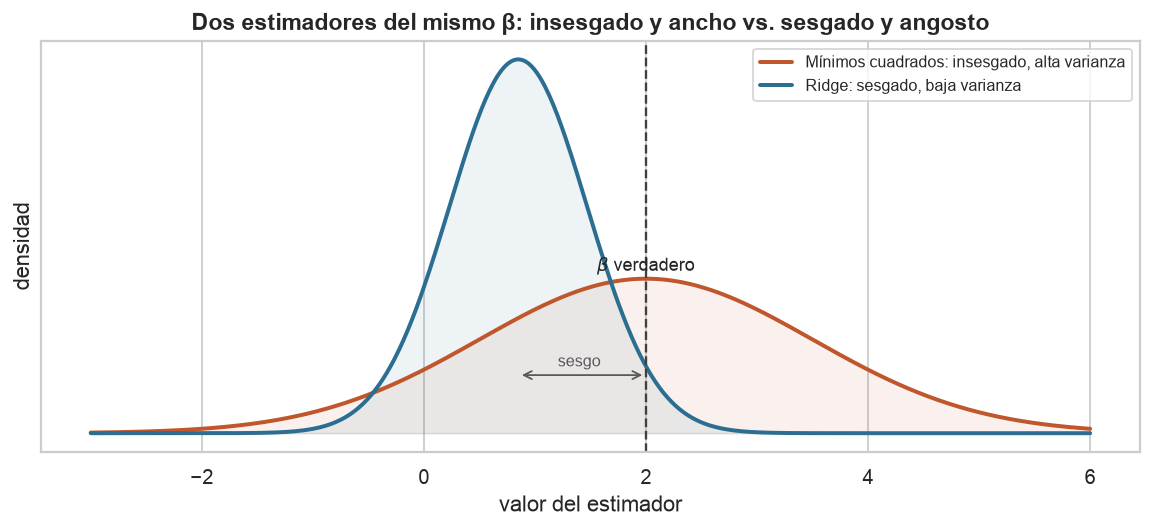

In [44]:
# Figura conceptual: el compromiso sesgo–varianza (ESL, cap. 2 y 7)
import numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import norm
sns.set_theme(style="whitegrid", context="notebook")
PAL, PAL2, ACCENT = "#2c6e91", "#c0562b", "#3a8f5e"
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 130, "savefig.bbox": "tight",
                     "font.size": 11, "axes.titleweight": "bold", "axes.titlesize": 12.5,
                     "figure.autolayout": True})

b_true = 2.0
xx = np.linspace(-3, 6, 500)
mc = norm(loc=b_true, scale=1.5)         # insesgado, pero ancho (alta varianza)
rg = norm(loc=b_true - 1.15, scale=0.62)  # sesgado, pero angosto (baja varianza)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(xx, mc.pdf(xx), color=PAL2, lw=2.2, label="Mínimos cuadrados: insesgado, alta varianza")
ax.fill_between(xx, mc.pdf(xx), color=PAL2, alpha=.08)
ax.plot(xx, rg.pdf(xx), color=PAL, lw=2.2, label="Ridge: sesgado, baja varianza")
ax.fill_between(xx, rg.pdf(xx), color=PAL, alpha=.08)
ax.axvline(b_true, color="0.25", ls="--", lw=1.3)
ax.annotate(r"$\beta$ verdadero", (b_true, mc.pdf(b_true)*1.05), ha="center", fontsize=10)
ax.annotate("", xy=(b_true, 0.10), xytext=(b_true - 1.15, 0.10),
            arrowprops=dict(arrowstyle="<->", color="0.35"))
ax.text((b_true - 0.6), 0.115, "sesgo", ha="center", color="0.35", fontsize=9)
ax.set(title="Dos estimadores del mismo β: insesgado y ancho vs. sesgado y angosto",
       xlabel="valor del estimador", ylabel="densidad", yticks=[])
ax.legend(loc="upper right", fontsize=9); plt.show()

La figura resume la apuesta. El estimador de MC (naranja) está **centrado en el valor verdadero**
pero su curva es ancha: en la única muestra que tenemos, puede caer lejos del centro. El estimador
Ridge (azul) está **corrido** —tiene sesgo— pero su curva es angosta: es más probable que caiga cerca
de donde cayó. Si el ahorro de varianza compensa el sesgo que agregamos, el ECM baja y predecimos
mejor. Esa es la lógica que comparten Ridge y Lasso.

### Ridge

Ridge (Hoerl & Kennard, 1970) minimiza la suma de cuadrados de siempre, pero **penalizada** por el
tamaño de los coeficientes al cuadrado:

$$\min_{\beta}\ \sum_{i=1}^{n}\big(y_i - \beta_0 - \textstyle\sum_j \beta_j x_{ij}\big)^2 \;+\; \lambda \sum_{j=1}^{p}\beta_j^2.$$

El parámetro $\lambda \ge 0$ lo elegimos nosotros. Con $\lambda = 0$ recuperamos MC; a medida que
$\lambda$ crece, los coeficientes se **encogen** hacia cero (por eso Ridge y Lasso se llaman
*estimadores de encogimiento* o *métodos de regularización*). Tres aclaraciones que importan
en la práctica (Hastie, Tibshirani & Friedman, 2009, cap. 3): (i) los coeficientes de Ridge **no tienen una interpretación tan limpia** como los de
MC —acá lo que interesa es predecir, no leer cada β—; (ii) el método es **sensible a la escala**, así
que hay que **estandarizar** los predictores antes de penalizar; y (iii) la penalización **no afecta al
intercepto**. Lo que Ridge **no** hace es anular coeficientes: los achica, pero rara vez los deja
exactamente en cero, así que **no selecciona variables**.

### Lasso

Lasso (Tibshirani, 1996) cambia un solo detalle de la fórmula —penaliza la suma de los **valores
absolutos** en lugar de los cuadrados—:

$$\min_{\beta}\ \sum_{i=1}^{n}\big(y_i - \beta_0 - \textstyle\sum_j \beta_j x_{ij}\big)^2 \;+\; \lambda \sum_{j=1}^{p}|\beta_j|.$$

Ese cambio aparentemente menor tiene una consecuencia grande: ahora los coeficientes **pueden valer
exactamente cero**. Por eso Lasso es, al mismo tiempo, un método de estimación **y** de **selección de
variables**: la lista de las que quedan sale sola. La razón es geométrica, y conviene verla con un
dibujo.

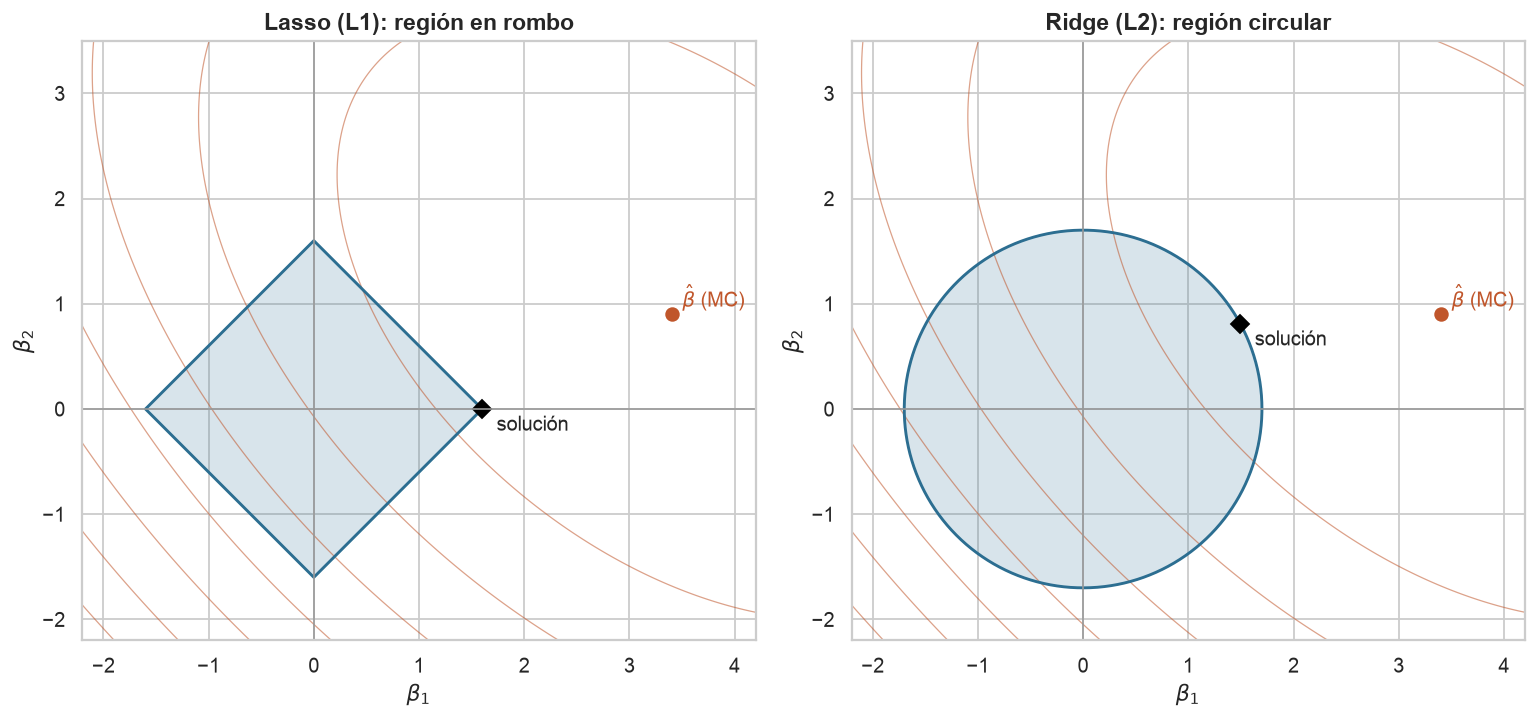

Contacto Lasso  ≈ (1.60, 0.00)   →  β2 prácticamente nulo (selección)
Contacto Ridge  ≈ (1.49, 0.81)   →  ambos coeficientes ≠ 0


In [45]:
# Intuición geométrica: por qué Lasso anula coeficientes y Ridge no (figura estilo ISL, cap. 6)
bhat = np.array([3.4, 0.9])                      # solución MC (sin restricción)
A = np.array([[1.0, 0.5], [0.5, 1.2]])           # forma de las elipses de SCE (predictoras correlacionadas)
def sce(b): d = b - bhat; return d @ A @ d

# contacto de la elipse con cada región de restricción (búsqueda numérica sobre el borde)
t = 1.6
seg = np.linspace(0, 1, 500); V = [(t,0),(0,t),(-t,0),(0,-t)]
borde_l1 = np.vstack([np.array(V[k])*(1-seg[:,None]) + np.array(V[(k+1)%4])*seg[:,None] for k in range(4)])
p_l1 = borde_l1[np.array([sce(b) for b in borde_l1]).argmin()]
r = 1.7; th = np.linspace(0, 2*np.pi, 1000); borde_l2 = np.c_[r*np.cos(th), r*np.sin(th)]
p_l2 = borde_l2[np.array([sce(b) for b in borde_l2]).argmin()]

b1 = np.linspace(-2.2, 4.2, 300); b2 = np.linspace(-2.2, 3.5, 300); B1, B2 = np.meshgrid(b1, b2)
Z = A[0,0]*(B1-bhat[0])**2 + 2*A[0,1]*(B1-bhat[0])*(B2-bhat[1]) + A[1,1]*(B2-bhat[1])**2

fig, axs = plt.subplots(1, 2, figsize=(12, 5.4))
for ax, region, punto, titulo in [
        (axs[0], np.array([[t,0],[0,t],[-t,0],[0,-t],[t,0]]), p_l1, "Lasso (L1): región en rombo"),
        (axs[1], np.c_[r*np.cos(th), r*np.sin(th)], p_l2, "Ridge (L2): región circular")]:
    ax.contour(B1, B2, Z, levels=9, colors=[PAL2], linewidths=.7, alpha=.55)
    ax.fill(region[:,0], region[:,1], color=PAL, alpha=.18); ax.plot(region[:,0], region[:,1], color=PAL, lw=1.6)
    ax.plot(*bhat, "o", color=PAL2, ms=7); ax.annotate(r"$\hat\beta$ (MC)", bhat, textcoords="offset points", xytext=(6,4), color=PAL2)
    ax.plot(*punto, "D", color="black", ms=7); ax.annotate("solución", punto, textcoords="offset points", xytext=(8,-12))
    ax.axhline(0, color="0.6", lw=.9); ax.axvline(0, color="0.6", lw=.9)
    ax.set(title=titulo, xlabel=r"$\beta_1$", ylabel=r"$\beta_2$", aspect="equal")
plt.show()
print(f"Contacto Lasso  ≈ ({p_l1[0]:.2f}, {p_l1[1]:.2f})   →  β2 prácticamente nulo (selección)")
print(f"Contacto Ridge  ≈ ({p_l2[0]:.2f}, {p_l2[1]:.2f})   →  ambos coeficientes ≠ 0")

Las **elipses naranjas** son curvas de igual suma de cuadrados alrededor de la solución de MC
$\hat\beta$; la **región azul** es la restricción que impone la penalización (cuanto más fuerte el
$\lambda$, más chica la región). La solución regularizada es el punto donde la elipse más interna
**toca** la región. Y ahí está la diferencia: la región de Ridge es un **círculo** (bordes suaves), así
que el contacto casi siempre cae **fuera de los ejes** → ningún coeficiente se anula. La región de
Lasso es un **rombo** con **vértices sobre los ejes**, y las elipses tienden a tocar justo en esas
esquinas → uno de los coeficientes queda **exactamente en cero**. Como se ve en la salida, el contacto
del Lasso tiene $\beta_2 \approx 0$: la variable quedó afuera. Eso es, en una imagen, por qué el Lasso
selecciona y Ridge no.

### ¿Ridge o Lasso? Y ElasticNet

En poder predictivo, ninguno le saca gran ventaja al otro. Como resume Tibshirani, **Lasso** suele
andar mejor cuando la respuesta depende de **unos pocos** predictores fuertes, y **Ridge** cuando hay
**muchas** variables con influencia parecida. El **ElasticNet** (Zou & Hastie, 2005) combina las dos
penalizaciones ($L_1 + L_2$) y es útil justamente cuando hay **grupos de predictores correlacionados**:
donde el Lasso elegiría uno del grupo casi al azar y descartaría el resto, ElasticNet los reparte de
forma más **estable**. En este notebook comparamos los tres contra el OLS del baseline, y usamos el
Lasso como herramienta de **selección** para ver qué variables aportan y cuáles son redundantes (RQ2).

## Metodología (protocolo experimental)

- **Datos y target:** matriz de modelado, escenario **S4** (el más completo); target
  $\log(1+\text{precio\_usd})$, métricas retransformadas a USD.
- **Particionado:** mismas **particiones group-aware** que el baseline (`GroupKFold`, 5 folds, grupo =
  `building_cluster_id`), para comparar de forma **pareada** contra el OLS y evitar fuga por
  republicaciones (Gutiérrez et al., 2026).
- **Preprocesamiento dentro del fold:** imputación + one-hot + **estandarización** —imprescindible para
  penalizar de forma justa (Kuhn & Johnson, 2013)—, ajustado solo con el train (ESL §7.10.2).
- **Elección de $\lambda$ sin fuga:** se tunea por **validación cruzada interna group-aware** dentro de
  cada fold de train (**nested CV**), de modo que la selección del modelo no contamine la estimación
  del error (ESL §7.10).

In [46]:
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, lasso_path
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists() and ROOT != ROOT.parent: ROOT = ROOT.parent
df = pd.read_csv(ROOT / "data" / "processed" / "zonaprop_v2_matriz_modelado_centro.csv.gz")
y = np.log1p(pd.to_numeric(df["eda_precio_usd"], errors="coerce").values)
groups = df["building_cluster_id"].values
feat_cols = [c for c in df.columns if c.startswith("feat_")]

S1 = ["eda_superficie_total_m2","eda_superficie_cubierta_m2","eda_ambientes","eda_dormitorios",
      "eda_banos","eda_cocheras","eda_toilette","eda_antiguedad_anos","eda_antiguedad_estado",
      "eda_disposicion","eda_orientacion","eda_tipo_operacion","eda_expensas",
      "fe_ratio_cubierta_total","fe_sup_por_ambiente","fe_banos_por_ambiente",
      "fe_dormitorios_por_ambiente","fe_tiene_cochera","fe_expensas_informadas"]
S2 = ["barrio_oficial_geo","eda_latitud","eda_longitud"]
S3 = [c for c in ["fe_dist_centro_km","fe_dist_rio_km","fe_dist_espacio_verde_km","fe_dens_comercios_300m"] if c in df.columns]
cols = [c for c in S1+S2+S3 if c in df.columns] + feat_cols   # S4 completo
CAT = {"eda_antiguedad_estado","eda_disposicion","eda_orientacion","eda_tipo_operacion","barrio_oficial_geo"}
BIN = set(feat_cols) | {"fe_tiene_cochera","fe_expensas_informadas"}
print(f"Matriz: {len(df):,} avisos · {df['building_cluster_id'].nunique():,} grupos · S4 con {len(cols)} columnas")

Matriz: 4,765 avisos · 1,377 grupos · S4 con 45 columnas


## Especificación del pipeline

El escalado va **después** del one-hot para que todos los coeficientes se penalicen en una escala
comparable (si no, una variable en miles de dólares y otra en 0/1 recibirían penalizaciones muy
distintas por el solo hecho de sus unidades). Todo el pipeline —imputación, one-hot, estandarización y
modelo— se ajusta **solo con el train** de cada fold.

In [47]:
def preprocesador(cols):
    cat = [c for c in cols if c in CAT]
    binz = [c for c in cols if c in BIN]
    num = [c for c in cols if c not in cat and c not in binz]
    return ColumnTransformer([
        ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                          ("o", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False))]), cat),
        ("bin", SimpleImputer(strategy="most_frequent"), binz),
        ("num", SimpleImputer(strategy="median"), num),
    ], remainder="drop")

def hacer_pipe(model):
    return Pipeline([("prep", preprocesador(cols)), ("sc", StandardScaler()), ("m", model)])

def nombres(prep):
    return [n.split("__", 1)[-1] for n in prep.get_feature_names_out()]

A_L1 = np.logspace(-4, 0, 18)     # grilla Lasso / ElasticNet (sobre datos estandarizados)
A_L2 = np.logspace(-2, 4, 18)     # grilla Ridge
L1R  = [0.3, 0.6, 0.9]            # l1_ratio ElasticNet
MAXIT = 5000                       # iteraciones máx. (converge holgado con datos estandarizados)
print("Pipeline y grillas de penalización definidos.")

Pipeline y grillas de penalización definidos.


### Dos decisiones que conviene explicitar

Antes de correr los modelos, vale la pena aclarar dos puntos que suelen generar dudas.

**Por qué regularizamos con el set S4 y no con "todas las columnas".** La regularización —y en particular
el Lasso— está pensada justamente para tragar **muchos** predictores y dejar que la penalización encoja
o apague los que no aportan. Por eso, dentro de los predictores *legítimos*, no preseleccionamos a mano:
los metemos todos y que decida el método (preseleccionar mirando la relación con el precio, además,
arriesgaría fuga). Ahora bien, eso **no** significa arrojarle las 124 columnas del dataset. Muchas de
esas columnas no son predictores: identificadores (`property_id`, o `building_cluster_id`, que acá usamos
como *grupo* de CV, no como variable), campos de linaje y auditoría, la URL, el texto crudo de la
descripción y las **distintas capas de una misma variable** (cruda / auditada / `eda_`). Incluir eso
estaría mal **más allá de regularizar**: algunas son fuga directa (un ID puede memorizar el precio) y
otras no son información válida. La matriz S4 ya viene curada para dejar solo predictores candidatos; la
selección estadística fina, esa sí, se la delegamos al Lasso.

**Dónde se estandariza.** Estandarizar es imprescindible (la penalización es sensible a la escala), pero
el *cuándo* importa: **no** se estandariza sobre todo el dataset antes de partir en folds, porque la
media y el desvío del test se filtrarían al train (fuga; ESL §7.10.2; Kuhn & Johnson, 2013). Por eso el
`StandardScaler` va **dentro** del pipeline: en cada fold se ajusta con el train y se aplica al test.
La única excepción es la matriz `Xf` que se arma más abajo para el **gráfico** de trayectorias de
coeficientes y la ilustración geométrica —ahí sí se escala sobre todo el dataset—, pero es un uso
puramente **descriptivo**: no interviene en ninguna estimación de error. Toda la performance (§1) y la
estabilidad (§4) usan el escalado por fold.

## 1. ¿Regularizar mejora la predicción? (OOF, comparación pareada)

Evaluamos OLS, Ridge, Lasso y ElasticNet sobre **las mismas 5 particiones**. Para cada fold, el
$\lambda$ de los modelos penalizados se tunea por CV interna group-aware; el OLS no tiene
hiperparámetro. Reportamos RMSE, MAE, MAPE y R²(log) fuera de muestra, más el número medio de
coeficientes activos.

In [48]:
def tune(base, grid, Xtr, ytr, gtr):
    gs = GridSearchCV(hacer_pipe(base), grid, cv=GroupKFold(4),
                      scoring="neg_mean_squared_error", n_jobs=-1)
    gs.fit(Xtr, ytr, groups=gtr); return gs.best_estimator_

def oof(base, grid):
    gkf = GroupKFold(5); filas, nz = [], []
    for tr, te in gkf.split(df, y, groups):
        est = hacer_pipe(base).fit(df.iloc[tr][cols], y[tr]) if grid is None \
              else tune(base, grid, df.iloc[tr][cols], y[tr], groups[tr])
        p = est.predict(df.iloc[te][cols])
        ytu, ypu = np.expm1(y[te]), np.expm1(p)
        filas.append(dict(rmse=np.sqrt(mean_squared_error(ytu, ypu)), mae=mean_absolute_error(ytu, ypu),
                          mape=np.mean(np.abs((ytu-ypu)/ytu))*100, r2=r2_score(y[te], p)))
        c = est.named_steps["m"].coef_; nz.append(int(np.sum(np.abs(c) > 1e-8)))
    r = pd.DataFrame(filas)
    return dict(RMSE_USD=r.rmse.mean(), RMSE_sd=r.rmse.std(), MAE_USD=r.mae.mean(),
                MAPE_pct=r.mape.mean(), R2_log=r.r2.mean(), R2_sd=r.r2.std(), coef_no_cero=np.mean(nz))

modelos = {"OLS": (LinearRegression(), None),
           "Ridge": (Ridge(), {"m__alpha": A_L2}),
           "Lasso": (Lasso(max_iter=MAXIT, tol=1e-3), {"m__alpha": A_L1}),
           "ElasticNet": (ElasticNet(max_iter=MAXIT, tol=1e-3), {"m__alpha": A_L1, "m__l1_ratio": L1R})}
perf = pd.DataFrame({k: oof(*v) for k, v in modelos.items()}).T
display(perf.round({"RMSE_USD":0,"RMSE_sd":0,"MAE_USD":0,"MAPE_pct":1,"R2_log":3,"R2_sd":3,"coef_no_cero":0}))

,RMSE_USD,RMSE_sd,MAE_USD,MAPE_pct,R2_log,R2_sd,coef_no_cero
OLS,64573.0,22816.0,30267.0,19.8,0.866,0.005,66.0
Ridge,63860.0,20468.0,30316.0,19.9,0.866,0.005,66.0
Lasso,63386.0,19026.0,30266.0,19.8,0.867,0.004,56.0
ElasticNet,62618.0,17419.0,30257.0,19.8,0.867,0.005,57.0


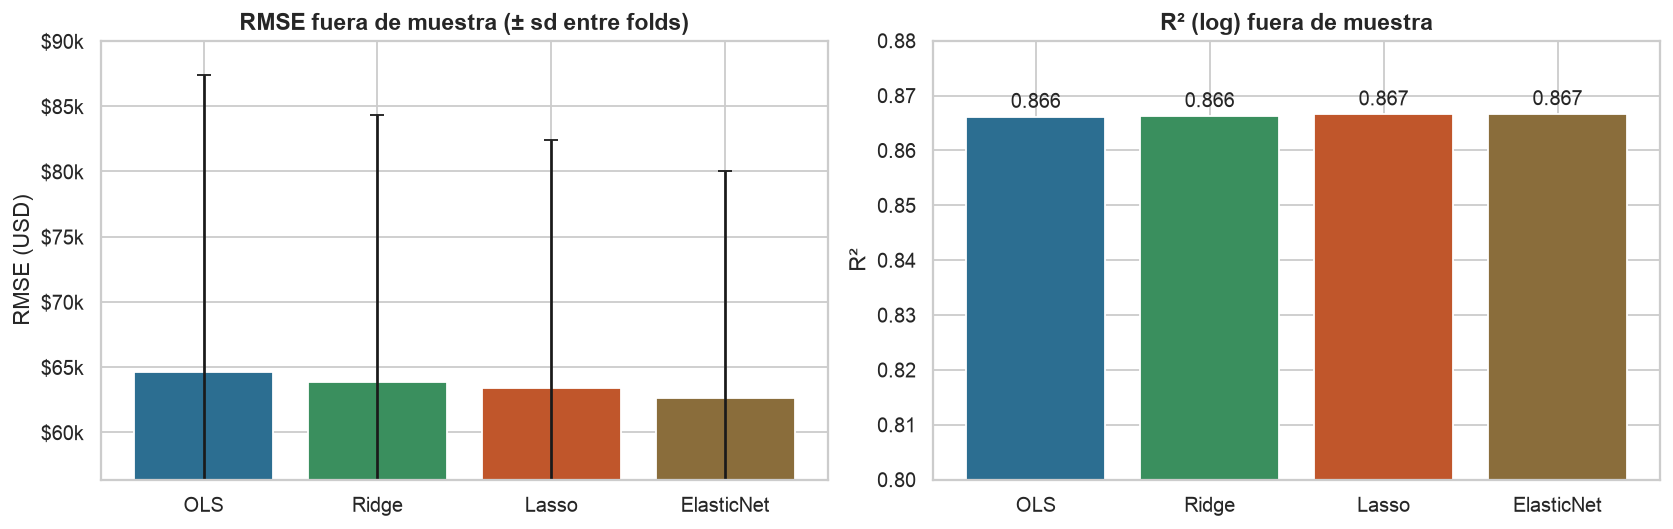

In [49]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
colores = [PAL, ACCENT, PAL2, "#8a6d3b"]
axs[0].bar(perf.index, perf["RMSE_USD"], color=colores, yerr=perf["RMSE_sd"], capsize=4)
axs[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f"${x/1e3:.0f}k"))
axs[0].set(title="RMSE fuera de muestra (± sd entre folds)", ylabel="RMSE (USD)")
axs[0].set_ylim(perf["RMSE_USD"].min()*0.9, (perf["RMSE_USD"]+perf["RMSE_sd"]).max()*1.03)
axs[1].bar(perf.index, perf["R2_log"], color=colores)
for i,v in enumerate(perf["R2_log"]): axs[1].annotate(f"{v:.3f}", (i,v), textcoords="offset points", xytext=(0,5), ha="center")
axs[1].set(title="R² (log) fuera de muestra", ylabel="R²"); axs[1].set_ylim(0.8, 0.88)
plt.show()

Lo primero que salta a la vista es que los cuatro modelos rinden **casi igual**: el R² se queda en
torno a 0,86 y el RMSE apenas se mueve. Podría decepcionar —uno esperaría que regularizar "mejore" el
modelo—, pero en realidad tiene sentido y conviene leerlo con cuidado. Con casi 4.800 avisos y del
orden de 60 columnas tenemos muchas más observaciones que parámetros, así que el OLS **no tiene mucho
margen para sobreajustar**; y si no hay sobreajuste que corregir, la penalización no puede hacer magia
con la exactitud.

Donde sí se nota la diferencia es en la **estabilidad**: el desvío del RMSE entre folds **baja de forma
monótona** de MC a ElasticNet, señal de que sus coeficientes son menos sensibles a qué propiedades
tocaron en cada partición. De hecho, **ElasticNet es el mejor comportado**: consigue a la vez el RMSE
más bajo y el menor desvío entre folds, tal como cabe esperar cuando hay predictores correlacionados
(Zou & Hastie, 2005). En términos del compromiso sesgo–varianza del que partimos, estamos pagando un
poco de sesgo a cambio de un modelo más estable, sin resignar capacidad predictiva. Y hay un beneficio
extra que explotamos enseguida: el Lasso deja **varios coeficientes en cero** (columna `coef_no_cero`),
así que además de predecir nos ayuda a decidir qué variables valen la pena.

## 2. Cómo encogen los coeficientes: Lasso vs. Ridge

Estas dos figuras muestran, para todo un rango de penalización, qué pasa con cada coeficiente. Es la
mejor forma de *ver* la diferencia entre los dos métodos. En ambos casos la penalización crece de
izquierda a derecha; cada línea es una variable.

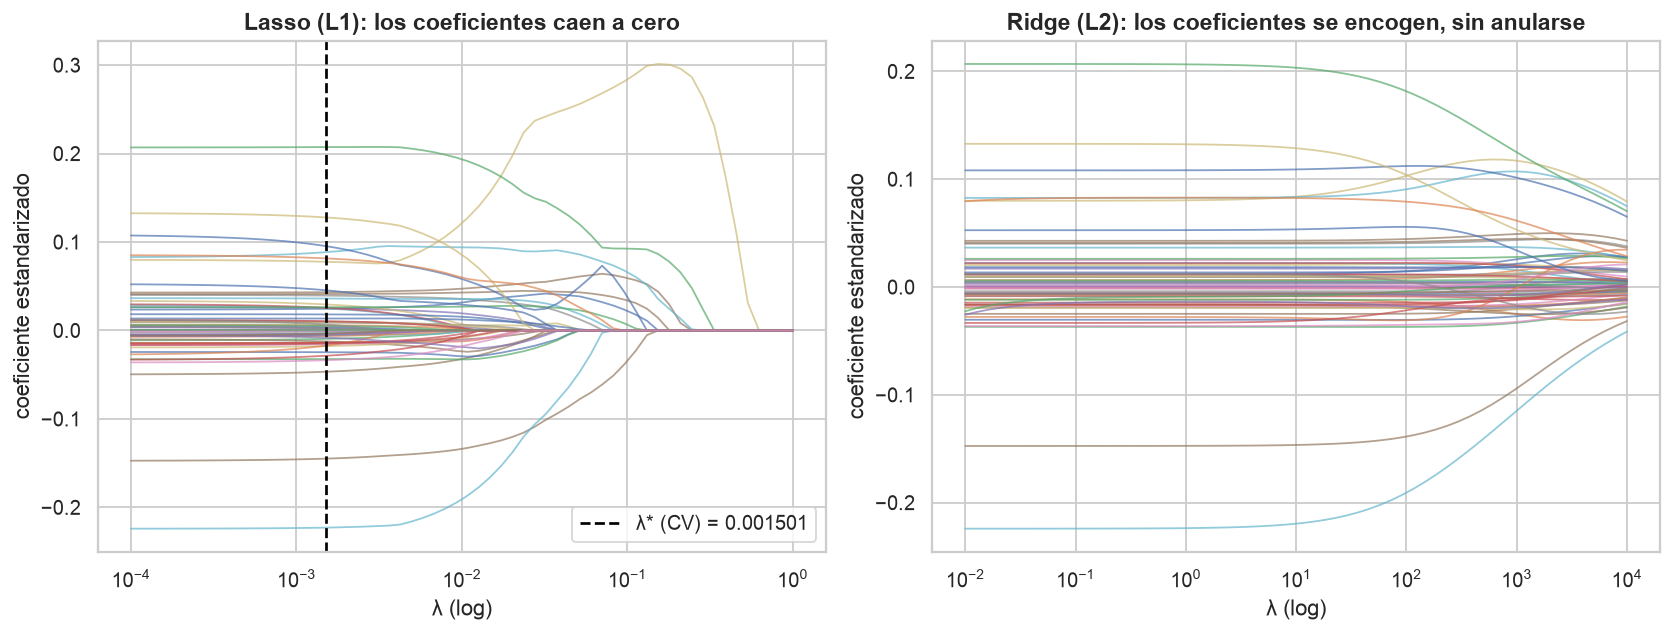

Lasso en λ*: 56 de 67 coeficientes ≠ 0


In [50]:
# matriz de diseño estandarizada sobre todo el dataset (para trayectorias y selección)
prep_full = preprocesador(cols).fit(df[cols])
Xf = StandardScaler().fit_transform(prep_full.transform(df[cols]))
names = nombres(prep_full)

# λ* del Lasso por CV group-aware
gs = GridSearchCV(hacer_pipe(Lasso(max_iter=MAXIT, tol=1e-3)), {"m__alpha": A_L1},
                  cv=GroupKFold(5), scoring="neg_mean_squared_error", n_jobs=-1).fit(df[cols], y, groups=groups)
alpha = gs.best_params_["m__alpha"]
coef_full = gs.best_estimator_.named_steps["m"].coef_
n_sel = int(np.sum(np.abs(coef_full) > 1e-8))

alphas_l, coefs_l, _ = lasso_path(Xf, y, alphas=np.logspace(-4, 0, 60))
al_r = np.logspace(-2, 4, 60)
coefs_r = np.array([Ridge(alpha=a).fit(Xf, y).coef_ for a in al_r]).T

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for j in range(coefs_l.shape[0]): axs[0].plot(alphas_l, coefs_l[j], lw=1, alpha=.7)
axs[0].axvline(alpha, color="black", ls="--", lw=1.5, label=f"λ* (CV) = {alpha:.4g}")
axs[0].set_xscale("log"); axs[0].set(title="Lasso (L1): los coeficientes caen a cero", xlabel="λ (log)", ylabel="coeficiente estandarizado"); axs[0].legend()
for j in range(coefs_r.shape[0]): axs[1].plot(al_r, coefs_r[j], lw=1, alpha=.7)
axs[1].set_xscale("log"); axs[1].set(title="Ridge (L2): los coeficientes se encogen, sin anularse", xlabel="λ (log)", ylabel="coeficiente estandarizado")
plt.show()
print(f"Lasso en λ*: {n_sel} de {len(names)} coeficientes ≠ 0")

La comparación es didáctica. En el **Lasso** (izquierda), a medida que sube $\lambda$ las líneas
van **tocando el cero y quedándose ahí**: las variables se apagan una a una, y las que resisten más
penalización antes de apagarse son las más informativas. En **Ridge** (derecha) las líneas se
**acercan** al cero de forma suave pero **nunca lo tocan**: todos los coeficientes siguen vivos, solo
más chicos. Esto es exactamente lo que anticipaba la intuición geométrica —vértices del rombo vs. borde
redondo del círculo— y explica por qué usamos el Lasso, y no Ridge, cuando lo que queremos es
**seleccionar**. La línea punteada marca el $\lambda^*$ que elegimos por validación cruzada: ni tan
chico que no penalice nada, ni tan grande que apague variables útiles.

## 3. Qué variables aportan y cuáles descarta el Lasso

En $\lambda^*$, los coeficientes **no nulos** son las variables que el Lasso considera informativas; las
que lleva a **cero exacto** son redundantes o sin señal marginal (su información ya está en otras).
Etiquetamos cada variable por su **bloque** (estructural, localización, microlocalización o texto) para
leer mejor de dónde viene la señal.

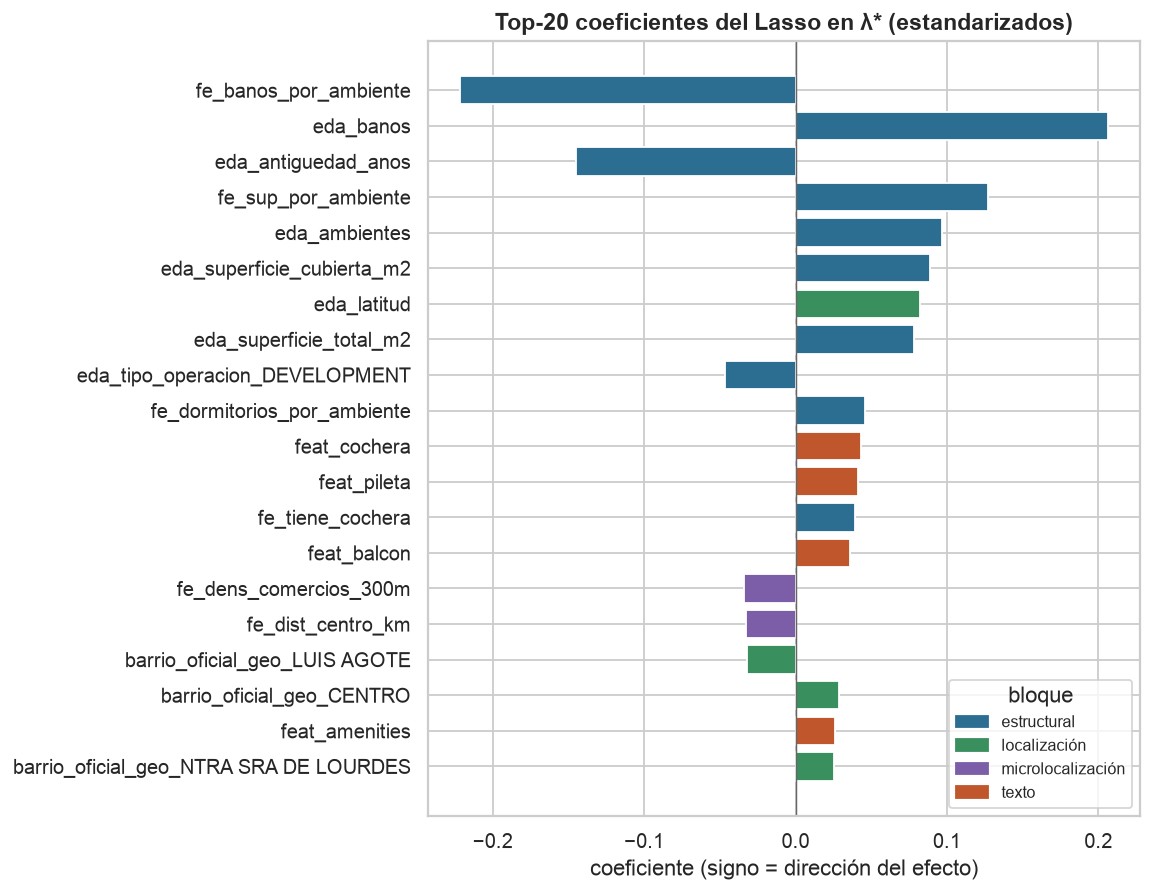

Descartadas por el Lasso (11):
  · eda_tipo_operacion_PROPERTY        [estructural]
  · eda_longitud                       [localización]
  · eda_disposicion_Contrafrente       [estructural]
  · eda_orientacion_O                  [estructural]
  · eda_expensas                       [estructural]
  · eda_orientacion_NE                 [estructural]
  · barrio_oficial_geo_ALBERTO OLMEDO  [localización]
  · feat_ascensor                      [texto]
  · feat_permite_mascotas              [texto]
  · eda_antiguedad_estado_Usado        [estructural]
  · eda_orientacion_SE                 [estructural]


In [51]:
def bloque(f):
    if f in S2 or f.startswith("barrio_"): return "localización"
    if f.startswith("fe_dist") or f == "fe_dens_comercios_300m": return "microlocalización"
    if f.startswith("feat_"): return "texto"
    return "estructural"

sel = pd.DataFrame({"feature": names, "coef": coef_full, "abs": np.abs(coef_full),
                    "bloque": [bloque(n) for n in names],
                    "seleccionada": np.abs(coef_full) > 1e-8}).sort_values("abs", ascending=False)
paleta = {"estructural": PAL, "localización": ACCENT, "microlocalización": "#7b5ea7", "texto": PAL2}
top = sel[sel.seleccionada].head(20)
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top["feature"][::-1], top["coef"][::-1], color=[paleta[b] for b in top["bloque"][::-1]])
ax.axvline(0, color="0.4", lw=0.8)
handles = [plt.Rectangle((0,0),1,1,color=c) for c in paleta.values()]
ax.legend(handles, paleta.keys(), title="bloque", loc="lower right", fontsize=9)
ax.set(title="Top-20 coeficientes del Lasso en λ* (estandarizados)", xlabel="coeficiente (signo = dirección del efecto)")
plt.show()

desc = sel[~sel.seleccionada][["feature","bloque"]]
print(f"Descartadas por el Lasso ({len(desc)}):")
for _, r in desc.iterrows(): print(f"  · {r.feature:<34} [{r.bloque}]")

Las variables de mayor peso son **estructurales** (baños y su ratio, superficie y ratios,
antigüedad, ambientes), acompañadas de algunas de **localización** (latitud, densidad comercial) y de
**texto** (cochera, pileta, balcón). Es tranquilizador que este orden **coincida con la jerarquía de
significancia del baseline** (notebook 01): dos caminos distintos —los p-valores del OLS y el
encogimiento del Lasso— señalan a los mismos protagonistas, lo que le da solidez a la lectura.

Entre las **descartadas** aparecen las que uno esperaría: `eda_longitud` —la posición este–oeste ya
está capturada por la distancia al río y al centro, con las que corre casi paralela—, `eda_expensas`
(que aporta poco una vez que controlamos superficie y ambientes), `feat_permite_mascotas`, y varias
**dummies** de orientación o de algún barrio con pocos casos. El mensaje de fondo es que **casi todas
las variables aportan** y el Lasso solo poda un grupo chico de redundantes, lo que respalda la decisión
de haber armado una matriz de modelado parca en lugar de inflarla con columnas.

### Tabla de coeficientes: cómo encoge cada método

Para ver el encogimiento de cerca, ajustamos los cuatro métodos sobre todo el dataset y ponemos sus
coeficientes lado a lado (cada uno con su $\lambda$ óptimo por CV). Son coeficientes **estandarizados**
—cada predictor entra con media 0 y desvío 1—, así que, a diferencia del notebook 01 (donde estaban en %
por unidad), acá **son comparables entre sí**: la magnitud mide la importancia relativa, y se leen, de
forma aproximada, como el cambio porcentual del precio ante un aumento de **un desvío** en el predictor.
Ordenamos por |coef. Lasso|.

In [52]:
def alpha_cv(model, grid):
    g = GridSearchCV(hacer_pipe(model), grid, cv=GroupKFold(5),
                     scoring="neg_mean_squared_error", n_jobs=-1).fit(df[cols], y, groups=groups)
    return g.best_estimator_.named_steps["m"].coef_

ols_c = LinearRegression().fit(Xf, y).coef_
ridge_c = alpha_cv(Ridge(), {"m__alpha": A_L2})
en_c = alpha_cv(ElasticNet(max_iter=MAXIT, tol=1e-3), {"m__alpha": A_L1, "m__l1_ratio": L1R})

tab = pd.DataFrame({"predictor": names, "MC": ols_c, "Ridge": ridge_c, "Lasso": coef_full, "ElasticNet": en_c})
tab = tab.reindex(tab["Lasso"].abs().sort_values(ascending=False).index).reset_index(drop=True)
display(tab.head(18).round(3))
print(f"Σ|coef|:  MC {np.abs(ols_c).sum():.2f}  ·  Ridge {np.abs(ridge_c).sum():.2f}  ·  "
      f"Lasso {np.abs(coef_full).sum():.2f}  ·  ElasticNet {np.abs(en_c).sum():.2f}")
print(f"coef ≠ 0: MC {int((np.abs(ols_c)>1e-8).sum())} · Ridge {int((np.abs(ridge_c)>1e-8).sum())} · "
      f"Lasso {int((np.abs(coef_full)>1e-8).sum())} · ElasticNet {int((np.abs(en_c)>1e-8).sum())}")

,predictor,MC,Ridge,Lasso,ElasticNet
0,fe_banos_por_ambiente,-0.224,-0.210,-0.221,-0.221
1,eda_banos,0.207,0.196,0.206,0.206
2,eda_antiguedad_anos,-0.147,-0.144,-0.145,-0.145
3,fe_sup_por_ambiente,0.133,0.120,0.127,0.127
4,eda_ambientes,0.108,0.111,0.097,0.098
5,eda_superficie_cubierta_m2,0.083,0.085,0.089,0.088
6,eda_latitud,-0.133,0.081,0.082,0.083
7,eda_superficie_total_m2,0.080,0.091,0.078,0.078
8,eda_tipo_operacion_DEVELOPMENT,-0.025,-0.025,-0.047,-0.047
9,fe_dormitorios_por_ambiente,0.053,0.055,0.046,0.047


Σ|coef|:  MC 3.63  ·  Ridge 1.95  ·  Lasso 1.85  ·  ElasticNet 1.86
coef ≠ 0: MC 67 · Ridge 67 · Lasso 56 · ElasticNet 57


**Cómo leer la tabla.** Al estar estandarizados, cada coeficiente dice cuánto cambia $\log(\text{precio})$
ante un aumento de **un desvío** del predictor; para valores chicos, multiplicar por 100 da el cambio
porcentual aproximado del precio. Con esa lente, un desvío más de **baños** se asocia a ~+21% y la
**antigüedad** pesa en sentido contrario (~−15% por desvío). Lo interesante de ponerlos lado a lado es
**ver el encogimiento en números**: la suma de los valores absolutos de los coeficientes cae de **3,63
en MC a ~1,9** en los tres métodos penalizados —casi la mitad—, y el Lasso además apaga 10.

Hay un caso que conviene mirar con lupa: **la latitud**. En MC su coeficiente es **−0,13**, pero en
Ridge, Lasso y ElasticNet cambia de signo a **+0,08**. Ese salto no es casualidad: es la firma de la
colinealidad. En MC la latitud entra junto con la longitud —con la que está muy correlacionada—, y esa
competencia vuelve inestable, y hasta con signo equivocado, a su coeficiente. Al regularizar, la
longitud se encoge (y el Lasso directamente la apaga), y la latitud se acomoda en un valor chico y
positivo y más plausible. Sería un ejemplo ilustrativo de por qué, ante predictores correlacionados, los
coeficientes de MC conviene tomarlos con cautela y la regularización tendería a estabilizarlos.

Para el resto de las variables los cuatro métodos **coinciden casi punto por punto**: las jerarquías se
mantienen, lo que sería consistente con que la señal principal es robusta. Un detalle a señalar: algún ratio aparece
con un signo que solo se entiende de forma **condicional** —por ejemplo, "baños por ambiente" resulta
negativo *dado* el número de baños y de ambientes, que ya están en el modelo—, así que estos
coeficientes se leen como asociaciones parciales, no como efectos aislados. Y si uno busca la lectura en
unidades interpretables (por baño, por m²), esa está en el modelo hedónico del notebook 01; acá el
objetivo es comparar la importancia entre variables y ver el efecto del encogimiento.

> **Una advertencia importante sobre las categóricas.** Cuando hay variables categóricas convertidas
> en *dummies*, el Lasso puede descartar **algunas dummies sueltas** de una misma variable (p. ej. deja
> `orientación = N` pero saca `orientación = NE`), y eso *rompe la lógica* de la categórica, porque en
> rigor sus niveles deberían entrar o salir **todos juntos**. Es justo lo que nos pasa con la orientación
> y con algún barrio. La solución principiada es el **Group Lasso** (Yuan & Lin, 2006; Choi et al.,
> 2012), que penaliza cada categórica como un bloque.
> Para nuestro objetivo —entender qué bloques de información pesan— el resultado sigue siendo válido, y
> las conclusiones sobre variables **numéricas de una sola columna** (longitud, expensas) no se ven
> afectadas por este punto; pero conviene leer el descarte de dummies individuales con esta cautela, y
> lo dejamos anotado como línea de mejora.

## 4. ¿Es estable la selección? (remuestreo por folds)

Una sola corrida de Lasso puede ser caprichosa: con predictores correlacionados, un pequeño cambio en
los datos puede hacer que se seleccione una variable del grupo en lugar de otra (esto es lo que motiva
al ElasticNet). La idea de la **selección estable** (Meinshausen & Bühlmann, 2010) es simple: reajustar
el Lasso en distintos subconjuntos y ver **con qué frecuencia** sobrevive cada variable. Las que quedan
en los cinco folds son robustas; las que entran y salen, frágiles.

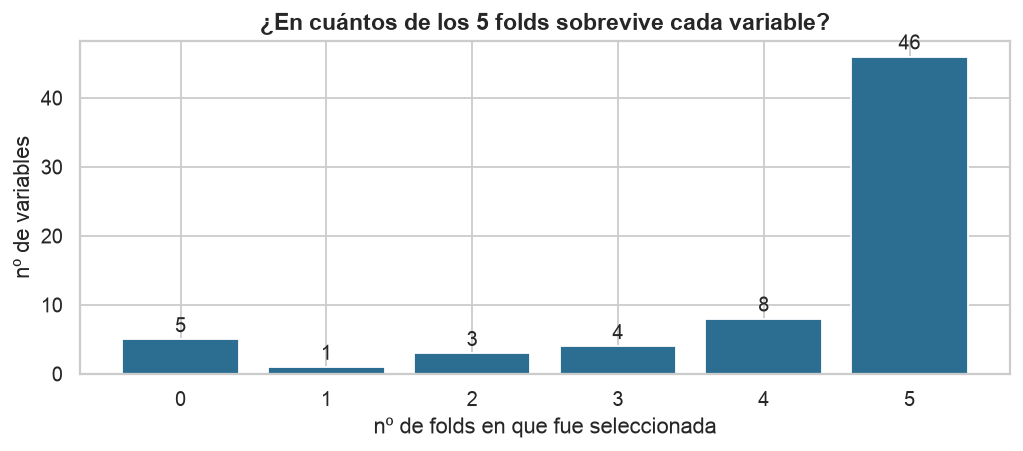

Robustas (5/5 folds): 46   ·   nunca (0/5): 5
Inestables (1–4 folds): 16 → ['fe_dist_centro_km', 'eda_antiguedad_estado_infrequent_sklearn', 'feat_lavadero', 'fe_dist_rio_km', 'feat_financiacion', 'fe_dist_espacio_verde_km', 'barrio_oficial_geo_PARQUE CASADO', 'feat_amoblado', 'eda_orientacion_SO', 'eda_orientacion_E', 'eda_orientacion_O', 'eda_expensas', 'eda_orientacion_NE', 'barrio_oficial_geo_ALBERTO OLMEDO', 'feat_ascensor', 'feat_permite_mascotas']


In [53]:
gkf = GroupKFold(5); freq = {n: 0 for n in names}
for tr, _ in gkf.split(df, y, groups):
    est = hacer_pipe(Lasso(alpha=alpha, max_iter=MAXIT, tol=1e-3)).fit(df.iloc[tr][cols], y[tr])
    for n, c in zip(nombres(est.named_steps["prep"]), est.named_steps["m"].coef_):
        if n in freq and abs(c) > 1e-8: freq[n] += 1
frq = pd.Series(freq).reindex(sel["feature"]).fillna(0).astype(int)

conteo = frq.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(conteo.index.astype(str), conteo.values, color=PAL)
for i, v in zip(conteo.index.astype(str), conteo.values): ax.annotate(str(v), (i, v), textcoords="offset points", xytext=(0,4), ha="center")
ax.set(title="¿En cuántos de los 5 folds sobrevive cada variable?", xlabel="nº de folds en que fue seleccionada", ylabel="nº de variables")
plt.show()

inestables = frq[(frq >= 1) & (frq <= 4)]
print(f"Robustas (5/5 folds): {int((frq==5).sum())}   ·   nunca (0/5): {int((frq==0).sum())}")
print(f"Inestables (1–4 folds): {len(inestables)} → {list(inestables.index)}")

La mayoría de las variables sobrevive en **los cinco folds**: son el núcleo robusto del modelo, y
son las mismas que encabezaban el ranking de coeficientes. Un grupo chico entra y sale según la
partición, y si uno mira cuáles son, no sorprende: **dummies ralas** (orientaciones, algún barrio con
pocos casos) y variables **correlacionadas** con otras del mismo bloque. Vale la pena señalar que entre
las inestables aparecen las **distancias de microlocalización** (`dist_centro`, `dist_rio`,
`dist_espacio_verde`, el bloque S3): es coherente con lo que vimos en el baseline (notebook 01), donde
ese bloque aportaba poco al ajuste lineal, y sugiere que su señal es débil o colineal *en un modelo
lineal*. Esa inestabilidad no es un error del método, sino su firma frente a la colinealidad
—exactamente el escenario para el que se pensó el ElasticNet, que en la sección 1 mostró menos
varianza—. Para la tesis, la conclusión práctica es quedarse con el núcleo robusto y tratar a las
frágiles con pinzas, apoyándose también en la significancia del baseline y, más adelante, en la
importancia por SHAP de los modelos de árboles.

## 5. Síntesis y conclusiones

Recapitulando lo que dejó este notebook:

- **En predicción, los cuatro modelos rinden de forma similar; ElasticNet aparece como el más parejo.**
  El R²(log) se ubica en ~0,87 y el MAPE en ~19,8% en todos, de modo que regularizar **no mejoraría la
  exactitud**: con ~4.800 avisos y del orden de 60 columnas, el MC del baseline **no exhibiría
  sobreajuste apreciable**, y sin sobreajuste que corregir la penalización tendría poco margen sobre la
  exactitud. La diferencia se observa en la **estabilidad**: el desvío del RMSE entre folds baja de forma
  monótona, de ~USD 22,8k en MC a ~USD 17,4k en ElasticNet, que además registra el RMSE puntual más bajo
  (~USD 62,6k). Sería el comportamiento que anticipa la teoría ante predictores correlacionados (Zou &
  Hastie, 2005), y ubicaría a **ElasticNet como el "lineal regularizado" de referencia** para la
  comparación contra los modelos de árboles.

- **El encogimiento, en números.** La suma de los valores absolutos de los coeficientes cae de **3,63 en
  MC a ~1,9** en los penalizados —casi a la mitad—, y el Lasso apaga 11 de 67 coeficientes. Es la
  definición de *shrinkage* hecha dato.

- **La regularización estabiliza coeficientes bajo colinealidad.** El caso más claro es la **latitud**:
  su coeficiente pasa de **−0,13 en MC a +0,08** en los tres métodos penalizados. El cambio de signo en
  MC venía de su competencia con la longitud (colineales); al regularizar, la longitud se encoge —el
  Lasso la apaga— y la latitud se acomoda en un valor chico, positivo y creíble.

- **La selección sería consistente con la matriz.** El Lasso descarta lo esperable (longitud, expensas,
  permite_mascotas, ascensor y dummies ralas de orientación/barrio) y **la mayoría de las variables
  aportan**. Que la jerarquía de coeficientes se mantenga estable entre los cuatro métodos, y que
  coincida con los p-valores del baseline, aportaría **evidencia convergente** a la interpretación.

- **Un hallazgo hacia adelante: la microlocalización (S3) es frágil en el modelo lineal.** Entre las
  variables inestables entre folds aparecen las **distancias** (`dist_centro`, `dist_rio`,
  `dist_espacio_verde`), lo que refuerza lo visto en el baseline (notebook 01): en forma lineal, ese
  bloque aporta poco. No es que la ubicación fina no importe, sino que su señal es débil o colineal en
  un modelo lineal —justo el tipo de variable que un modelo **no lineal** podría explotar mejor—.

**Consecuencia metodológica.** La **matriz de modelado se sostiene**: no hay variables que convenga
eliminar de plano, así que la selección fina se delega a la regularización **dentro del pipeline**, sin
podar a mano (lo que evita fuga y decisiones ad hoc). Con categóricas queda pendiente, como mejora, el
**Group Lasso** para tratar cada dummy como bloque. La importancia no lineal —y en particular si los
árboles rescatan la microlocalización— se retoma en la etapa siguiente con **Random Forest / LightGBM +
SHAP** (RQ1, RQ5).

## Referencias

**Libros**

- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2ª ed.), cap. 6. Springer.
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2ª ed.), cap. 3 y 7. Springer.
- Kuhn, M., & Johnson, K. (2013). *Applied Predictive Modeling*. Springer.
- Montgomery, D. C., Peck, E. A., & Vining, G. G. (2012). *Introduction to Linear Regression Analysis* (5ª ed.), cap. 9. Wiley.

**Artículos**

- Tibshirani, R. (1996). Regression shrinkage and selection via the Lasso. *JRSS-B, 58*(1), 267–288.
- Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67.
- Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. *JRSS-B, 67*(2), 301–320.
- Meinshausen, N., & Bühlmann, P. (2010). Stability selection. *JRSS-B, 72*(4), 417–473.
- Yuan, M., & Lin, Y. (2006). Model selection and estimation in regression with grouped variables. *JRSS-B, 68*(1), 49–67.
- Choi, N., Park, S., & Seo, J. (2012). *Lasso on categorical data* (Modified Group Lasso). Stanford CS229.